In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold

## Data exploration and visualization

### Load and inspect data

In [9]:
# Load train and test
train_df = pd.read_csv('trainCA4DAT200.csv')
test_df = pd.read_csv('testCA4DAT200.csv')

# Check shapes, dtypes, .head()
print("--- Train DataFrame ---")
print(f'\nShape: {train_df.shape}')
print(f'\nData types: {train_df.dtypes}')
display(train_df.head())
print("\n--- Test DataFrame ---")
print(f'\nShape: {test_df.shape}')
print(f'\nData types: {test_df.dtypes}')
display(test_df.head())


--- Train DataFrame ---

Shape: (3500, 21)

Data types: CustomerId                int64
State                    object
AccountLength             int64
AreaCode                  int64
InternationalPlan        object
VoiceMailPlan            object
NumVoiceMailMessages      int64
DayMinutes              float64
DayCalls                  int64
DayCharge               float64
EveMinutes              float64
EveCalls                  int64
EveCharge               float64
NightMinutes            float64
NightCalls                int64
NightCharge             float64
IntlMinutes             float64
IntlCalls                 int64
IntlCharge              float64
CustomerServiceCalls      int64
Churn                     int64
dtype: object


,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0



--- Test DataFrame ---

Shape: (1500, 20)

Data types: CustomerId                int64
State                    object
AccountLength             int64
AreaCode                  int64
InternationalPlan        object
VoiceMailPlan            object
NumVoiceMailMessages      int64
DayMinutes              float64
DayCalls                  int64
DayCharge               float64
EveMinutes              float64
EveCalls                  int64
EveCharge               float64
NightMinutes            float64
NightCalls                int64
NightCharge             float64
IntlMinutes             float64
IntlCalls                 int64
IntlCharge              float64
CustomerServiceCalls      int64
dtype: object


,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls
0,858315,MD,125,408,no,no,0,137.1,94,23.31,209.8,83,17.83,238.4,114,10.73,8.6,4,2.32,1
1,583988,WY,134,510,no,no,0,296.0,93,50.32,226.4,117,19.24,246.8,98,11.11,12.3,10,3.32,0
2,812674,NE,103,408,no,no,0,160.8,91,27.34,155.8,82,13.24,254.3,103,11.44,8.5,3,2.30,1
3,611702,ID,73,408,no,no,0,67.0,76,11.39,223.0,154,18.96,236.5,151,10.64,11.2,2,3.02,1
4,656308,OH,162,415,no,no,0,135.2,98,22.98,242.0,107,20.57,246.9,96,11.11,10.2,2,2.75,2


The train and test data has all the expected columns. 

### Explore the raw data

In [26]:
# Check for missing values
print("Missing values in train dataset:")
print(train_df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows in train dataset:")
print(train_df.duplicated().sum())

# Statistics summary
train_df.describe().T

Missing values in train dataset:
CustomerId              0
State                   0
AccountLength           0
AreaCode                0
InternationalPlan       0
VoiceMailPlan           0
NumVoiceMailMessages    0
DayMinutes              0
DayCalls                0
DayCharge               0
EveMinutes              0
EveCalls                0
EveCharge               0
NightMinutes            0
NightCalls              0
NightCharge             0
IntlMinutes             0
IntlCalls               0
IntlCharge              0
CustomerServiceCalls    0
Churn                   0
dtype: int64

Duplicate rows in train dataset:
0


,count,mean,std,min,25%,50%,75%,max
CustomerId,3500.0,545925.360857,261478.546087,101267.0,322381.00,536375.50,775246.7500,999391.00
AccountLength,3500.0,99.996571,39.471509,1.0,73.00,100.00,126.0000,243.00
AreaCode,3500.0,436.915429,42.169180,408.0,415.00,415.00,415.0000,510.00
NumVoiceMailMessages,3500.0,8.112000,13.728371,0.0,0.00,0.00,19.0000,52.00
DayMinutes,3500.0,180.292429,53.764503,0.0,143.70,179.70,216.5250,351.50
DayCalls,3500.0,100.016286,19.852587,0.0,87.00,100.00,113.0000,163.00
DayCharge,3500.0,30.650306,9.139923,0.0,24.43,30.55,36.8125,59.76
EveMinutes,3500.0,200.763000,50.561814,0.0,165.90,201.05,235.2250,361.80
EveCalls,3500.0,100.178000,19.800506,0.0,87.00,100.00,113.0000,170.00
EveCharge,3500.0,17.065066,4.297740,0.0,14.10,17.09,19.9925,30.75


We can see that there are no missing or duplicate values. From looking at the min, and max values for each category, we can also conclude that there are no impossible values (e.g. negative values)

In [31]:
# Check unique values for categorical columns

for col in ["State", "AreaCode", "InternationalPlan", "VoiceMailPlan"]:
    print(col, train_df[col].nunique())
    print(train_df[col].value_counts(dropna=False).head(10), "\n")

State 51
State
WV    121
OH     91
NY     88
AL     88
OR     81
UT     80
TX     80
MN     79
NJ     78
VA     78
Name: count, dtype: int64 

AreaCode 3
AreaCode
415    1766
510     871
408     863
Name: count, dtype: int64 

InternationalPlan 2
InternationalPlan
no     3168
yes     332
Name: count, dtype: int64 

VoiceMailPlan 2
VoiceMailPlan
no     2530
yes     970
Name: count, dtype: int64 



We see that we have only yes/no values for InternationalPlan and VoiceMailPlan, which means we have no impossible values here, and do not need to deal with capitalization / different spelling. 

AreaCode has 3 unique values, State has 51. 

### Check for outliers

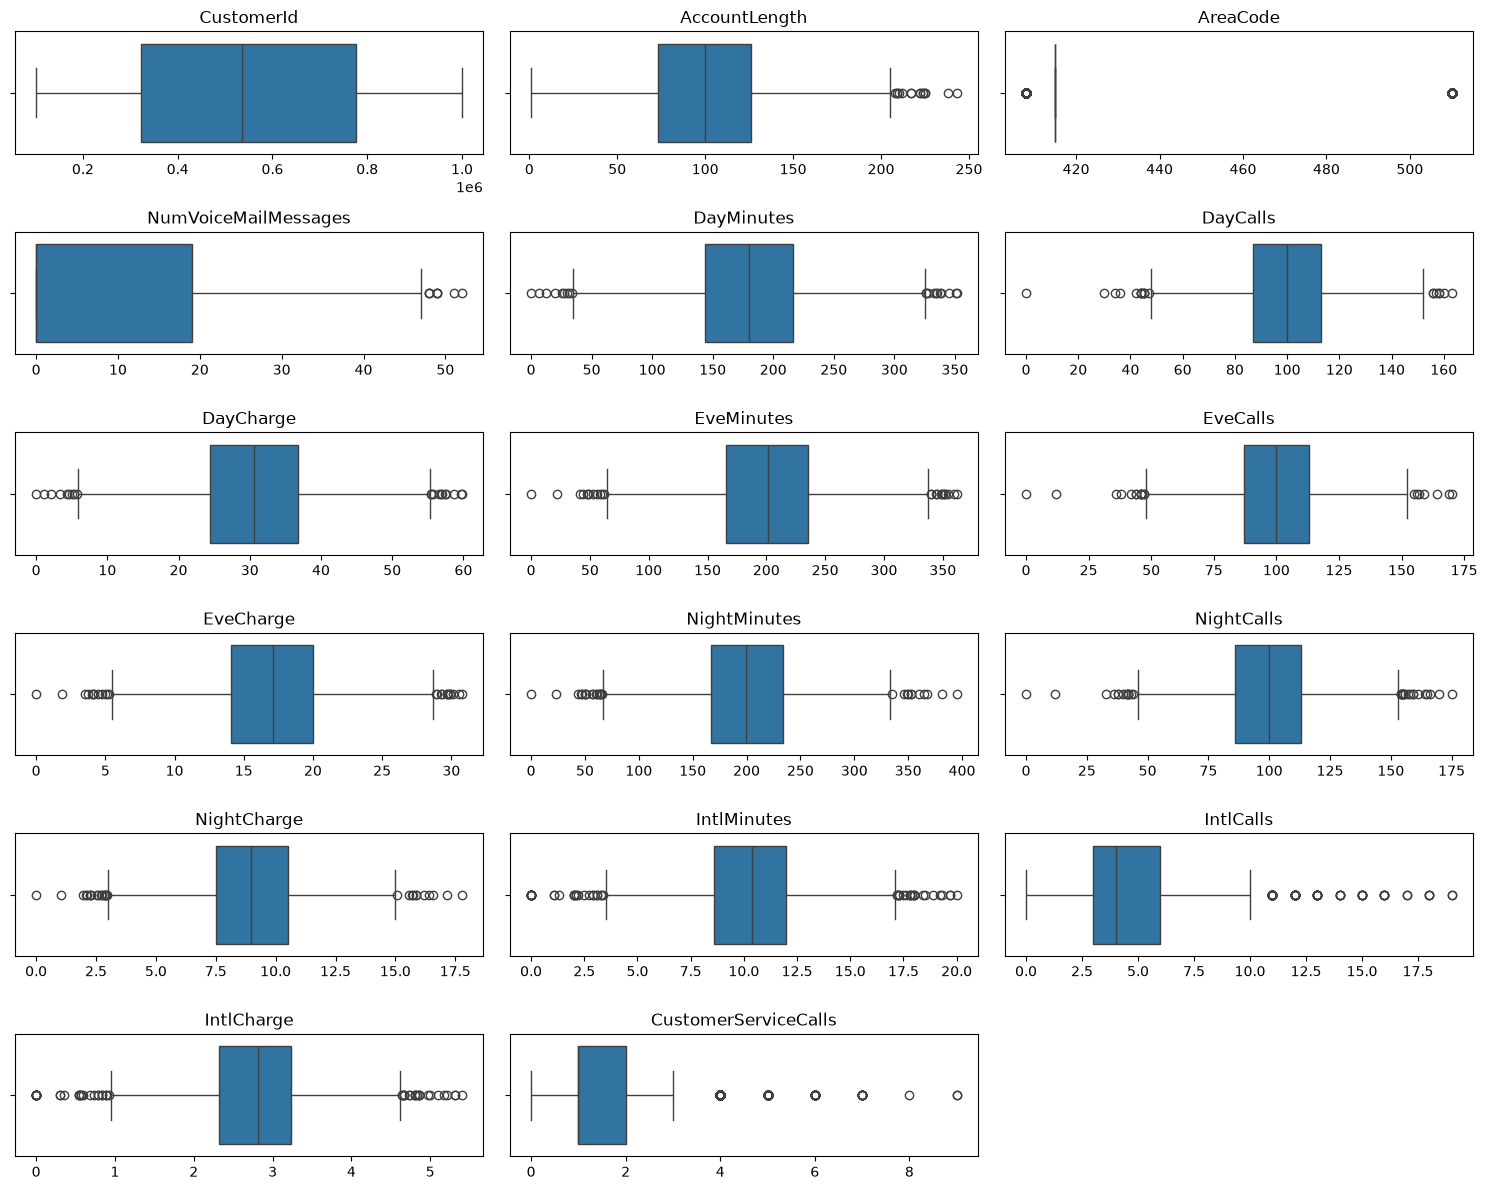

In [30]:
# Set up grid for boxplots
fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(15, 12))
axes = axes.flatten() # 1D array for easier indexing

# Iterate through columns and create boxplots
# Use all columns of type float64 and int64, except target (churn)
selected_columns = train_df.select_dtypes(include=['float64', 'int64']).columns
selected_columns = selected_columns[selected_columns != 'Churn']  # Exclude target variable
for i, col in enumerate(selected_columns):
    sns.boxplot(x=train_df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    
# Remove unused  18th box
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Correlation heatmap

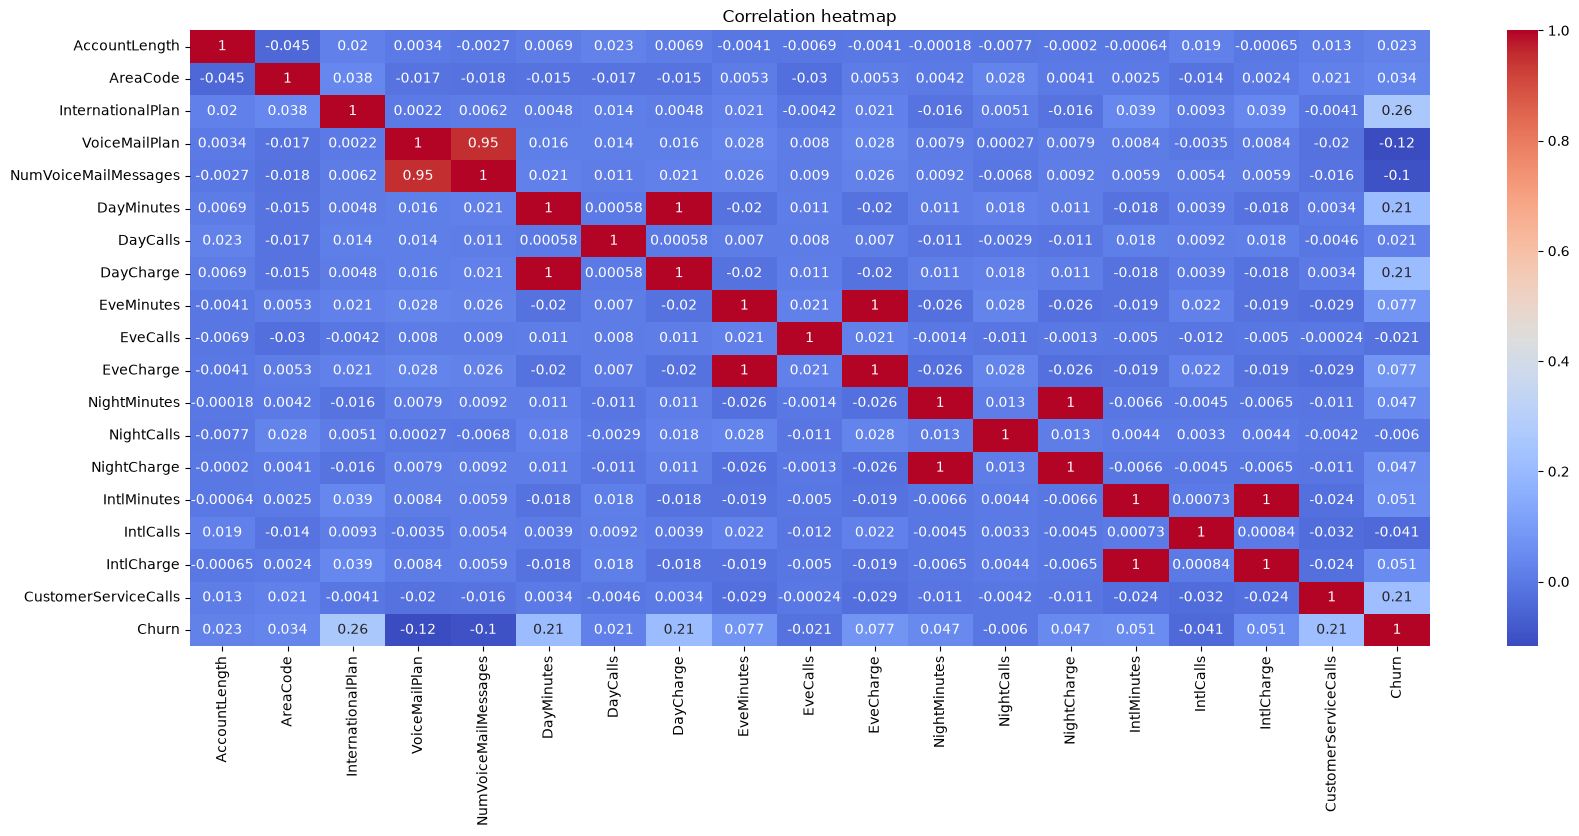

In [22]:
# Change 'InternationalPlan' and 'VoiceMailPlan' to binary yes=1, no=0
df = train_df.copy()
df["InternationalPlan"] = df["InternationalPlan"].map({"yes": 1, "no": 0})
df["VoiceMailPlan"] = df["VoiceMailPlan"].map({"yes": 1, "no": 0})

# Compute correlation matrix 
correlation_matrix = df.drop(columns=["CustomerId"]).corr(numeric_only=True)

# Plot heatmap of correlation matrix
plt.figure(figsize=(20, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

To determine the correlation between the features and the target we look at the churn-row and look for the highest absolute values. The correlation from highest to lowest is therefore: 

1. InternationalPlan: 0.26

2. DayMinutes: 0.21
2. DayCharge: 0.21
2. CustomerServiceCalls: 0.21

3. VoiceMailPlan: -0.12

4. NumVoiceMailMessages: -0.1

5. EveMinutes: 0.077
5. EveCharge: 0.077

6. IntlMinutes: 0.051
6. IntlCharge: 0.051

7. NightMinutes: 0.047
7. NightCharge: 0.047

8. IntlCalls: -0.041

9. AreaCode: 0.034

10. AccountLength: 0.023

11. DayCalls: 0.021
11. EveCalls: -0.021

12. NightCalls: -0.006

Based on this information, we can experiment with different feature selections in training different models, and see what gives us the best results. 

### Churn rate per category

We want to look at the churn rate for some selected categories, since the correlation heatmap only shows linear relationships.

This bit of code is generated by Claude: https://claude.ai/. 
The comments in the code are written by us, to explain in our own words what the code does

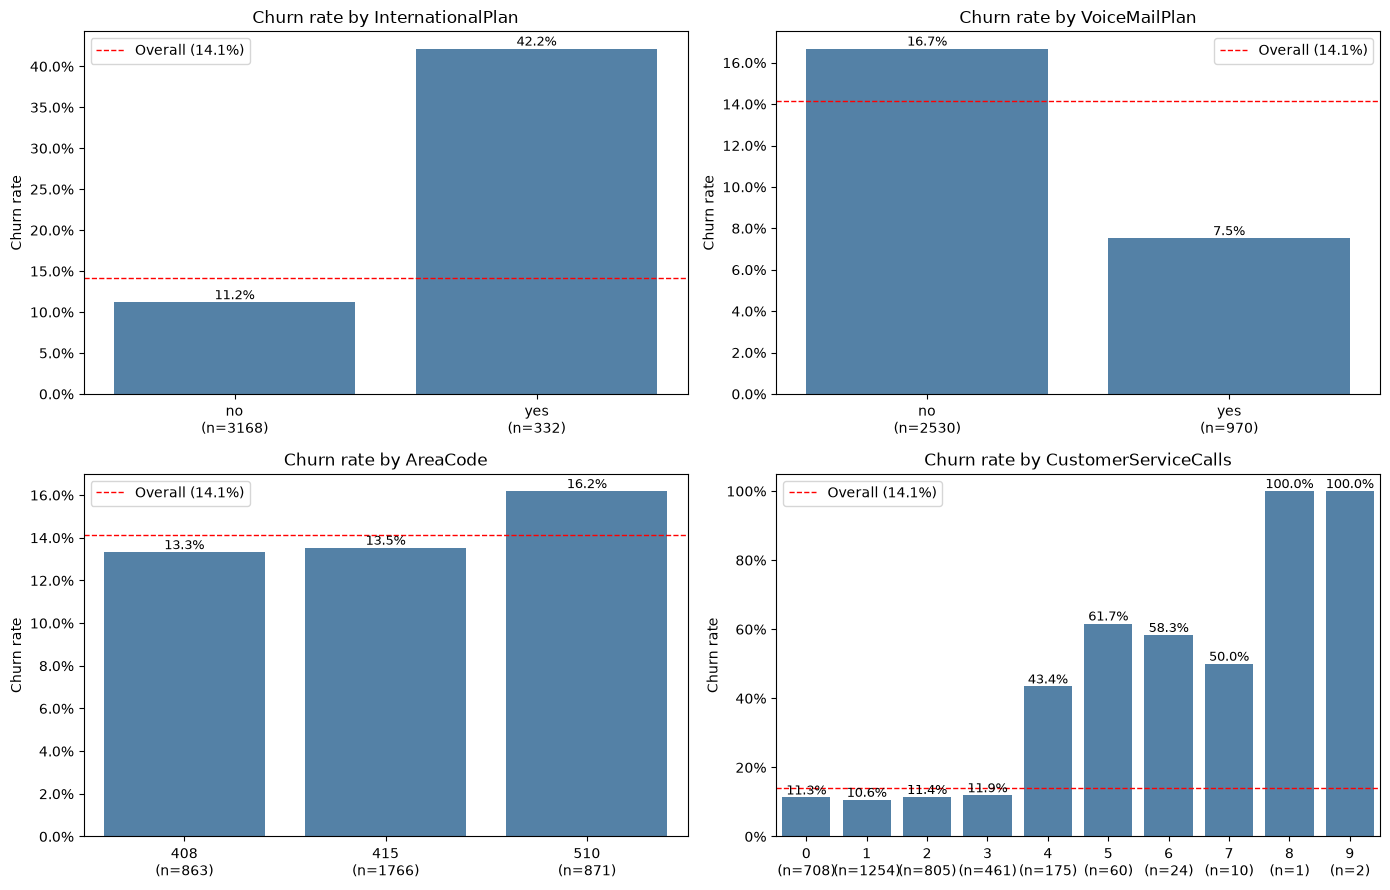

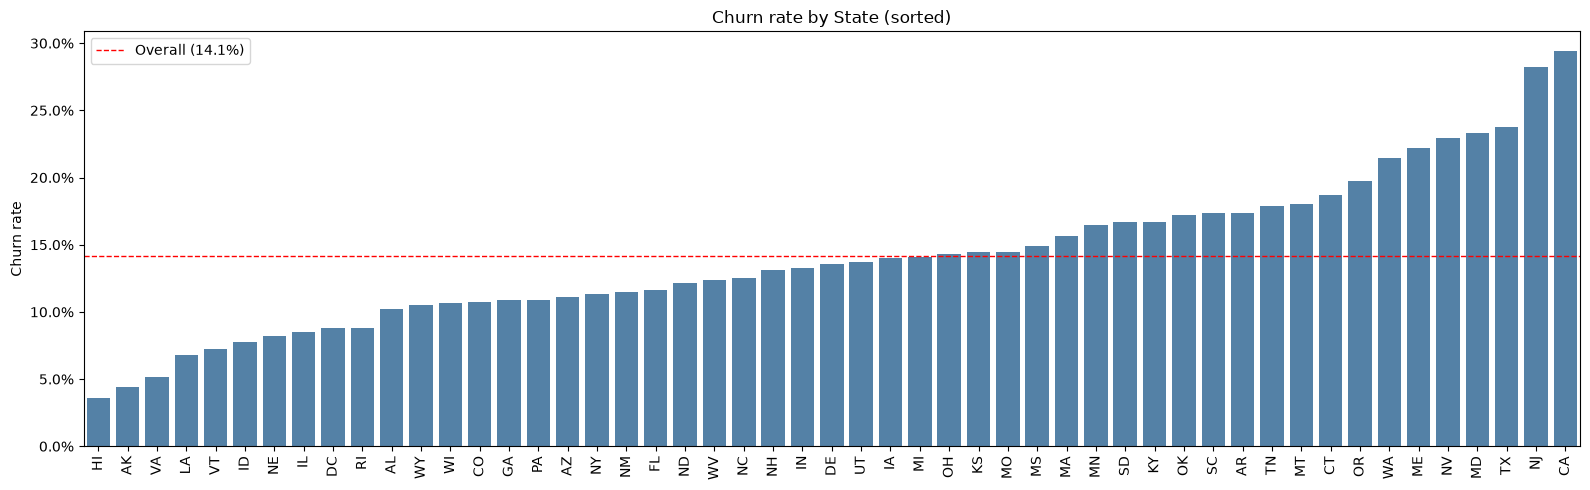

In [37]:
# Calculate the overall churn rate for reference in plots
overall = train_df["Churn"].mean()

# Define a function to plot churn rate by category
def churn_rate_plot(col, ax, title=None):
    """Bar plot of churn rate per category, with group sizes (n) under the labels."""
    # Compute churn rate and group sizes
    stats = train_df.groupby(col)["Churn"].agg(rate="mean", n="size").reset_index()
    # Create bar plot
    sns.barplot(data=stats, x=col, y="rate", ax=ax, color="steelblue")
    # Format the overall churn rate line and add it to the plot
    ax.axhline(overall, color="red", linestyle="--", linewidth=1,
               label=f"Overall ({overall:.1%})")
    # Add percentage labels on top of the bars
    ax.bar_label(ax.containers[0], labels=[f"{r:.1%}" for r in stats["rate"]], fontsize=9)
    # Set x-ticks and labels with group sizes
    ax.set_xticks(range(len(stats)))
    ax.set_xticklabels([f"{c}\n(n={n})" for c, n in zip(stats[col], stats["n"])])
    # Set title and labels, format y-axis as percentage
    ax.set_title(title or f"Churn rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    # Add legend 
    ax.legend()

# Plot the categorical features using the function defined above
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
churn_rate_plot("InternationalPlan", axes[0, 0])
churn_rate_plot("VoiceMailPlan", axes[0, 1])
churn_rate_plot("AreaCode", axes[1, 0])
churn_rate_plot("CustomerServiceCalls", axes[1, 1])
plt.tight_layout()
plt.show()

# Make a bigger plot for State, sorted by churn rate
# Compute the churn rate and group sizes for each state, then sort by churn rate 
state_stats = (train_df.groupby("State")["Churn"]
               .agg(rate="mean", n="size")
               .sort_values("rate")
               .reset_index())
# Create a bar plot 
fig, ax = plt.subplots(figsize=(16, 5))
sns.barplot(data=state_stats, x="State", y="rate", ax=ax, color="steelblue")
# Add overall churn rate line
ax.axhline(overall, color="red", linestyle="--", linewidth=1,
           label=f"Overall ({overall:.1%})")
# Add title, labels, and format y-axis as percentage, rotate x--ticks and add legend
ax.set_title("Churn rate by State (sorted)")
ax.set_ylabel("Churn rate")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.xticks(rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

### Check class balance of churn

Churn counts
Churn
0    3005
1     495
Name: count, dtype: int64

Churn percentages
Churn
0    0.859
1    0.141
Name: proportion, dtype: float64


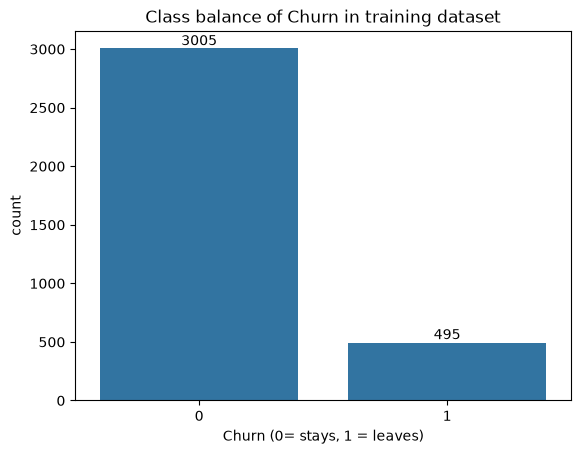

In [38]:
# Counts and percentages
print("Churn counts")
print(train_df["Churn"].value_counts())
print("\nChurn percentages")
print(train_df["Churn"].value_counts(normalize=True).round(3))

# Plot
ax = sns.countplot(x="Churn", data=train_df)
ax.bar_label(ax.containers[0]) # show the counts on top of the bars
plt.title("Class balance of Churn in training dataset")
plt.xlabel("Churn (0= stays, 1 = leaves)")
plt.show()

The churn rate is 14.1%, so the data is imbalances. This is something we have to take into account when making the models.  

### Check test set

In [39]:
# Missing, duplicate and impossible values
print("Missing values in test:\n", test_df.isnull().sum())
print("\nDuplicate rows in test:", test_df.duplicated().sum())
print("\nDescribe test")
display(test_df.describe().T)

Missing values in test:
 CustomerId              0
State                   0
AccountLength           0
AreaCode                0
InternationalPlan       0
VoiceMailPlan           0
NumVoiceMailMessages    0
DayMinutes              0
DayCalls                0
DayCharge               0
EveMinutes              0
EveCalls                0
EveCharge               0
NightMinutes            0
NightCalls              0
NightCharge             0
IntlMinutes             0
IntlCalls               0
IntlCharge              0
CustomerServiceCalls    0
dtype: int64

Duplicate rows in test: 0

Describe test


,count,mean,std,min,25%,50%,75%,max
CustomerId,1500.0,563744.628000,254561.935975,102187.00,341171.2500,583238.000,777220.5000,999302.00
AccountLength,1500.0,100.870000,40.216821,1.00,73.0000,100.500,128.0000,233.00
AreaCode,1500.0,436.902000,42.316453,408.00,408.0000,415.000,438.7500,510.00
NumVoiceMailMessages,1500.0,6.922667,13.078636,0.00,0.0000,0.000,0.0000,50.00
DayMinutes,1500.0,180.280667,54.215261,0.00,143.6750,181.500,215.9000,346.80
DayCalls,1500.0,100.060000,19.787777,0.00,87.0000,100.000,114.0000,165.00
DayCharge,1500.0,30.648180,9.216592,0.00,24.4250,30.860,36.7000,58.96
EveMinutes,1500.0,200.341533,50.542416,31.20,167.1750,200.950,232.1250,363.70
EveCalls,1500.0,100.221333,19.893588,37.00,87.0000,100.000,114.0000,168.00
EveCharge,1500.0,17.029253,4.296079,2.65,14.2075,17.085,19.7325,30.91


No missing, duplicate or imposssible values in test set.

In [40]:
# Check for new categories that dont appear in the training set
for col in ["State", "AreaCode", "InternationalPlan", "VoiceMailPlan"]:
    print(col, "-> only in test:", set(test_df[col]) - set(train_df[col]))

State -> only in test: set()
AreaCode -> only in test: set()
InternationalPlan -> only in test: set()
VoiceMailPlan -> only in test: set()


No new categories

In [41]:
# Check that CustomerId is unique and dont overlap between the train and test set

print("\nDuplicate IDs in train:", train_df["CustomerId"].duplicated().sum())
print("IDs in both train and test:", len(set(train_df["CustomerId"]) & set(test_df["CustomerId"])))


Duplicate IDs in train: 0
IDs in both train and test: 0


No duplicate CustomerIds between the train and test sets

## Data cleaning

As we saw, there were no missing, duplicate or impossible values in either the train set or test set. We will keep outliers since they are plausible values and can contribute meaningful information to the model. For example, we see in the plot for churn rates by CustomerServiceCall that the rate increases significantly for higher numbers of calls. 

For the cleaning we will do the following:
- Change InternationalPlan and VoiceMailPlan to binary (yes=1, no=0)
- AreaCode to string, so its treated as a category
- Drop CustomerId from the features, but keep the testIDs for the Kaggle submission

We create a function, so it can easily be reused when training our models. 

In [47]:
def clean(df):
    df = df.copy()
    
    # Convert InternationalPlan and VoiceMailPlan to binary
    for col in ["InternationalPlan", "VoiceMailPlan"]:
        df[col] = df[col].map({"yes": 1, "no": 0})
        
    # Convert AreaCode to string
    df["AreaCode"] = df["AreaCode"].astype(str)
    
    # Double check that there are no missing values
    assert df.isnull().sum().sum() == 0
    
    return df
            


## Create Cross-Validation setup

Use StratifiedKFold from Scikit-learn to create cross-validation setup to be used when training models. 

* 5 folds of 700 customers each. Since there are only about 490 churners, this is a good amount of folds to ensure there are enough churners in each validation fold
* Shuffle the rows before splitting, so folds don't depend on the order of the file
* use random_state=42, so the shuffle is reproducible and all group members get identical folds 
* Stratified means that every fold keeps the same churn percentage as the full training set, 14.1%. 

In [ ]:
RANDOM_STATE = 42
SCORING = "f1_macro" # primary evaluation metric

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Functions for data loading, cleaning, and cv-setup are added to `common.py` so it can be imported to all files for training models